# Synthetic Braille Page Generation — Step-by-Step Visualization
Each cell below implements and visualizes one step of the algorithm, building progressively toward a complete synthetic page.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random

plt.rcParams['mathtext.fontset'] = 'cm'  # Computer Modern-like math rendering, no LaTeX install needed
random.seed(7)
np.random.seed(7)

def show(img, title="", cmap="gray"):
    plt.figure(figsize=(6,6))
    plt.imshow(img, cmap=cmap)
    plt.title(title, fontsize=13)
    plt.axis("off")
    plt.show()

## Step 1 — Canvas and Scale Setup
Working canvas $I \in \mathbb{R}^{H \times W}$ at supersample factor $k$; scale $s$ (px/mm) drawn from a two-mode distribution.

Canvas: 800x1120, scale s=6.64, dot radius r_d=4.98


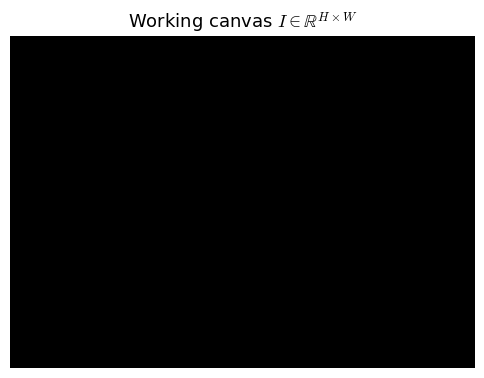

In [2]:
k = 2
H_o, W_o = 400, 560
H, W = k*H_o, k*W_o

p_s = 0.35
if random.random() < p_s:
    s = random.uniform(3.2, 4.0)
else:
    s = random.uniform(4.5, 5.5)
s *= k

r_d   = 0.75 * s
delta = 2.5 * s
c_w   = 6.0 * s
c_h   = 10.0 * s

canvas = np.ones((H, W), dtype=np.float32)
print(f"Canvas: {H}x{W}, scale s={s:.2f}, dot radius r_d={r_d:.2f}")
show(canvas, r"Working canvas $I \in \mathbb{R}^{H \times W}$")

## Step 2 — Character Encoding
Character id $\rightarrow$ 6-bit dot pattern $\beta = \text{reverse}(\text{binary}_6(\text{id}+1))$.

In [3]:
def id_to_bits(char_id):
    char_id = max(0, min(62, char_id))
    binary = format(char_id + 1, "06b")
    return binary[::-1]

for cid in [0, 1, 26, 62]:
    print(f"id={cid:2d} -> beta={id_to_bits(cid)}")

id= 0 -> beta=100000
id= 1 -> beta=010000
id=26 -> beta=110110
id=62 -> beta=111111


## Step 3 — Generic Dot Profile (constant radius r)
$$\phi(d,\theta)=\begin{cases}1 & d\le \rho r\\ \cos^{\eta}(\tfrac{\pi}{2}t),\ t=\dfrac{d-\rho r}{(1-\rho)r} & \rho r < d < r\\ 0 & \text{otherwise}\end{cases}$$

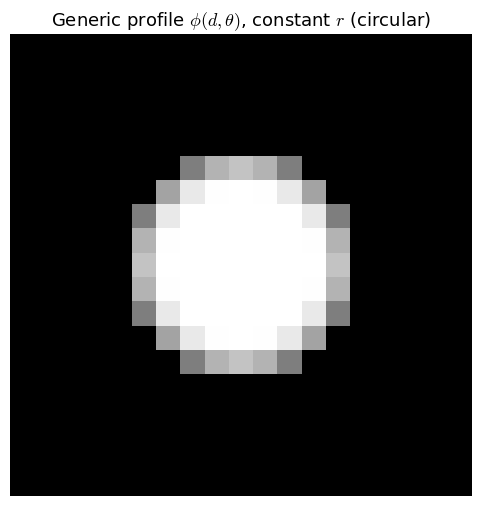

In [4]:
def dot_profile_generic(radius, rho=0.6, eta=0.75, size_mult=4):
    size = int(radius * size_mult)
    if size % 2 == 0:
        size += 1
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    c = size / 2.0 - 0.5
    d = np.sqrt((yy - c)**2 + (xx - c)**2)

    phi = np.zeros((size, size), dtype=np.float32)
    phi[d <= rho*radius] = 1.0
    band = (d > rho*radius) & (d < radius)
    span = max(radius - rho*radius, 1e-6)
    t = np.clip((d - rho*radius) / span, 0, 1)
    phi[band] = np.cos(t[band] * (np.pi/2)) ** eta
    return phi

phi_generic = dot_profile_generic(r_d)
show(phi_generic, r"Generic profile $\phi(d,\theta)$, constant $r$ (circular)")

## Step 4 — Angularly Perturbed Radius and Final Dot Profile
$$\hat r(\theta) = r\left(1+\varepsilon\, \hat n(\theta)\right)$$
Substituting $\hat r(\theta)$ for $r$ gives the dot actually rendered, with an irregular edge instead of a perfect circle.

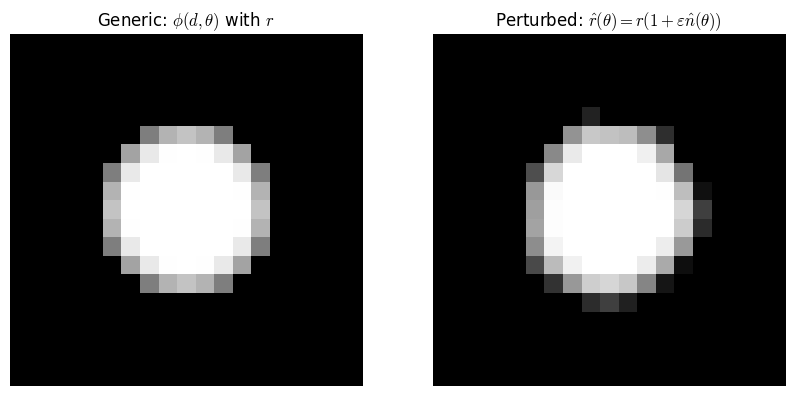

In [5]:
def angular_noise(theta, n_octaves=4, base_points=5):
    theta_norm = (theta + np.pi) / (2*np.pi)
    wobble = np.zeros_like(theta)
    amp_total = 0.0
    for o in range(n_octaves):
        n_pts = max(3, int(base_points * (2**o)))
        ctrl = np.random.uniform(-1, 1, n_pts+1)
        ctrl[-1] = ctrl[0]
        xs = np.linspace(0, 1, n_pts+1)
        octave = np.interp(theta_norm, xs, ctrl)
        amp = 1.0 / (o+1)**1.1
        wobble += octave * amp
        amp_total += amp
    return wobble / amp_total

def dot_profile_perturbed(radius, rho=0.6, eta=0.75, epsilon=0.15, size_mult=4):
    size = int(radius * size_mult)
    if size % 2 == 0:
        size += 1
    yy, xx = np.mgrid[0:size, 0:size].astype(np.float32)
    c = size / 2.0 - 0.5
    d = np.sqrt((yy - c)**2 + (xx - c)**2)
    theta = np.arctan2(yy - c, xx - c)

    r_hat = radius * (1 + epsilon * angular_noise(theta))

    phi = np.zeros((size, size), dtype=np.float32)
    phi[d <= rho*r_hat] = 1.0
    band = (d > rho*r_hat) & (d < r_hat)
    span = np.maximum(r_hat - rho*r_hat, 1e-6)
    t = np.clip((d - rho*r_hat) / span, 0, 1)
    phi[band] = np.cos(t[band] * (np.pi/2)) ** eta
    return phi

phi = dot_profile_perturbed(r_d)

fig, ax = plt.subplots(1, 2, figsize=(10,5))
ax[0].imshow(phi_generic, cmap="gray"); ax[0].set_title(r"Generic: $\phi(d,\theta)$ with $r$"); ax[0].axis("off")
ax[1].imshow(phi, cmap="gray"); ax[1].set_title(r"Perturbed: $\hat{r}(\theta) = r(1+\varepsilon\hat{n}(\theta))$"); ax[1].axis("off")
plt.show()

## Step 5 — Compositing Dots into a Layer via Entrywise Maximum
$$H_\ell[y_c-o:y_c+o+1,\ x_c-o:x_c+o+1] \leftarrow \max\big(H_\ell[\cdots],\ \phi\big)$$

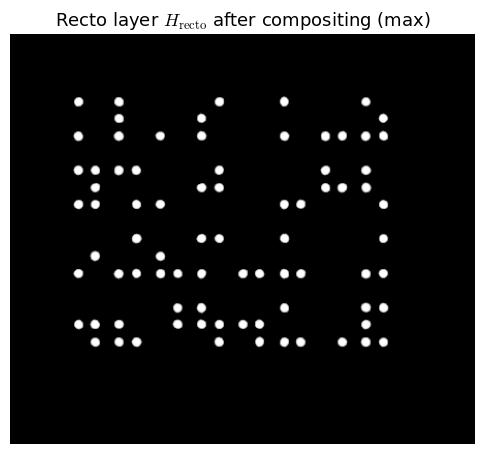

In [6]:
def stamp_cell(layer, px, py, bits, dot_radius, dx_pitch, dy_pitch):
    for i, bit in enumerate(bits):
        if bit == "1":
            dx = (i // 3) * dx_pitch
            dy = (i % 3) * dy_pitch
            x_c, y_c = int(px + dx), int(py + dy)
            bump = dot_profile_perturbed(dot_radius)
            bh, bw = bump.shape
            o = bh // 2
            y1, y2 = y_c-o, y_c-o+bh
            x1, x2 = x_c-o, x_c-o+bw
            if 0 <= y1 and y2 < layer.shape[0] and 0 <= x1 and x2 < layer.shape[1]:
                layer[y1:y2, x1:x2] = np.maximum(layer[y1:y2, x1:x2], bump)

H_recto = np.zeros((H, W), dtype=np.float32)
margin = int(20 * s / k)  # small demo margin
n_cols, n_rows = 8, 4
for r in range(n_rows):
    for c in range(n_cols):
        if random.random() > 0.1:
            char_id = random.randint(0, 62)
            bits = id_to_bits(char_id)
            px = margin + c * c_w
            py = margin + r * c_h
            stamp_cell(H_recto, px, py, bits, r_d, delta, delta)

show(H_recto[:int(4*c_h+2*margin), :int(8*c_w+2*margin)], r"Recto layer $H_{\mathrm{recto}}$ after compositing (max)")

## Step 6 — Cell Degradation
$$\phi \leftarrow \begin{cases}u\cdot\phi,\ u\sim\mathcal{U}(0.5,0.8) & \text{worn}\\ \phi * K_\theta & \text{smeared}\\ \phi \odot M(B) & \text{torn}\end{cases}$$

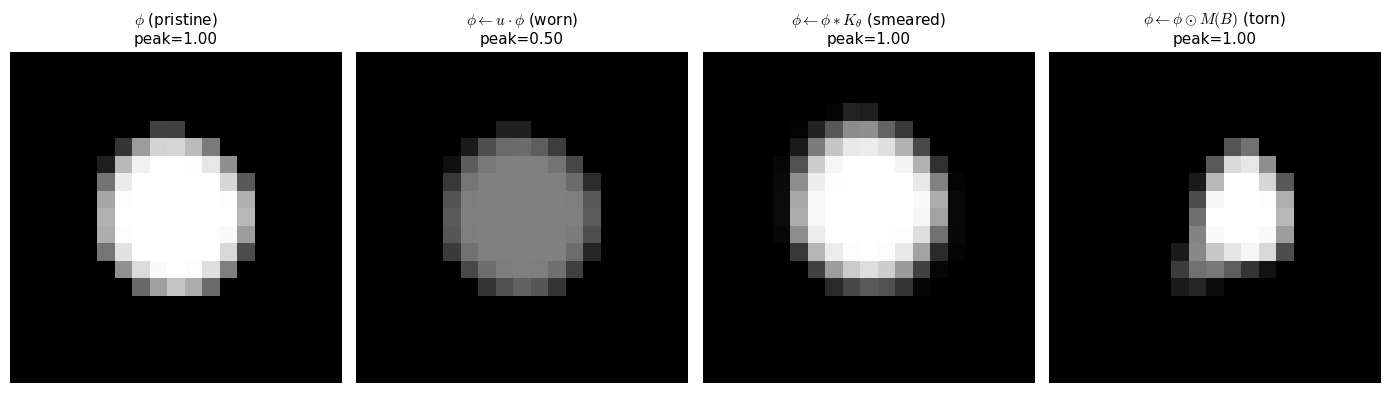

In [7]:
def degrade(bump, mode):
    h, w = bump.shape
    if mode == "worn":
        # Production range is u ~ U(0.5, 0.8). For a *legible* demo we fix
        # u at the low (more visibly dimmed) end of that range; the effect
        # is a uniform peak-brightness reduction, which can look subtle at
        # small figure size against a mostly-zero (black) background.
        u = 0.5
        return bump * u
    if mode == "smeared":
        length = random.randint(2, max(2, int(w*0.25)))
        angle = random.uniform(0, 360)
        kernel = np.zeros((length, length), dtype=np.float32)
        kernel[length//2, :] = 1.0
        Mrot = cv2.getRotationMatrix2D((length/2, length/2), angle, 1)
        kernel = cv2.warpAffine(kernel, Mrot, (length, length))
        kernel /= kernel.sum() + 1e-6
        return cv2.filter2D(bump, -1, kernel)
    if mode == "torn":
        # Production threshold (0.9) keeps only the top ~5-10% of the noise
        # field, which at this patch size can miss the dot entirely or leave
        # only a few scattered pixels. For legibility we use a milder
        # threshold (0.6) so the torn structure is clearly visible.
        for _ in range(10):
            low = np.random.normal(0, 1, (10, 10)).astype(np.float32)
            blob = cv2.resize(low, (w, h), interpolation=cv2.INTER_CUBIC)
            blob = cv2.GaussianBlur(blob, (0,0), sigmaX=w*0.15)
            blob = (blob - blob.min()) / (blob.max() - blob.min() + 1e-6)
            mask = np.clip((blob - 0.6)/0.1, 0, 1)
            result = bump * mask
            if (result > 0.05).mean() > 0.08:
                return result
        return bump * mask
    return bump

base = dot_profile_perturbed(r_d)
fig, ax = plt.subplots(1, 4, figsize=(14,4))
titles = {
    "pristine": r"$\phi$ (pristine)",
    "worn": r"$\phi \leftarrow u\cdot\phi$ (worn)",
    "smeared": r"$\phi \leftarrow \phi * K_\theta$ (smeared)",
    "torn": r"$\phi \leftarrow \phi \odot M(B)$ (torn)",
}
for a, mode in zip(ax, ["pristine", "worn", "smeared", "torn"]):
    b = base if mode == "pristine" else degrade(base.copy(), mode)
    a.imshow(b, cmap="gray", vmin=0, vmax=1)
    a.set_title(titles[mode] + f"\npeak={b.max():.2f}", fontsize=11)
    a.axis("off")
plt.tight_layout()
plt.show()

## Step 7 — Page-Wide Wear Map
$$H_{\text{recto}} \leftarrow H_{\text{recto}} \odot (1-\alpha W)$$

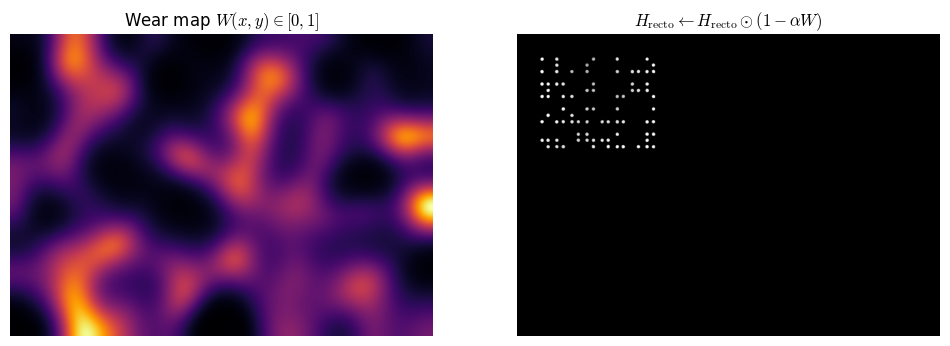

In [8]:
def generate_wear_map(H, W, scale):
    small = np.random.uniform(0, 1, (H // 40, W // 40))
    wear = cv2.resize(small.astype(np.float32), (W, H), interpolation=cv2.INTER_CUBIC)
    wear = cv2.GaussianBlur(wear, (0,0), sigmaX=scale*8)
    wear = (wear - wear.min()) / (wear.max() - wear.min() + 1e-6)
    return wear ** 3

wear_map = generate_wear_map(H, W, s)
alpha = 0.5
H_recto_worn = H_recto * (1 - alpha*wear_map)

fig, ax = plt.subplots(1, 2, figsize=(12,6))
ax[0].imshow(wear_map, cmap="inferno"); ax[0].set_title(r"Wear map $W(x,y) \in [0,1]$"); ax[0].axis("off")
ax[1].imshow(H_recto_worn, cmap="gray"); ax[1].set_title(r"$H_{\mathrm{recto}} \leftarrow H_{\mathrm{recto}} \odot (1-\alpha W)$"); ax[1].axis("off")
plt.show()

## Step 8 — Bounding Box Extraction
$$x_1 = p_x-r_d-p_b,\quad y_1=p_y-r_d-p_b,\quad x_2=p_x+\delta_h+r_d+p_b,\quad y_2=p_y+2\delta_v+r_d+p_b$$

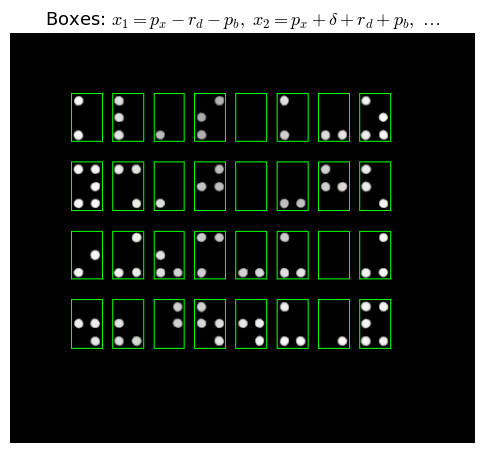

In [9]:
p_b = 0.25 * s
boxes = []
for r in range(n_rows):
    for c in range(n_cols):
        px = margin + c * c_w
        py = margin + r * c_h
        x1 = px - r_d - p_b
        y1 = py - r_d - p_b
        x2 = px + delta + r_d + p_b
        y2 = py + 2*delta + r_d + p_b
        boxes.append((x1, y1, x2, y2))

vis = cv2.cvtColor((H_recto_worn*255).astype(np.uint8), cv2.COLOR_GRAY2BGR)
for (x1,y1,x2,y2) in boxes:
    cv2.rectangle(vis, (int(x1),int(y1)), (int(x2),int(y2)), (0,255,0), 1)

crop = vis[:int(4*c_h+2*margin), :int(8*c_w+2*margin)]
show(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB), r"Boxes: $x_1=p_x-r_d-p_b,\ x_2=p_x+\delta+r_d+p_b,\ \ldots$", cmap=None)

## Step 9 — Recto/Verso Composition
$$\Phi = H_{\text{recto}} - 0.8\,H_{\text{verso}}$$

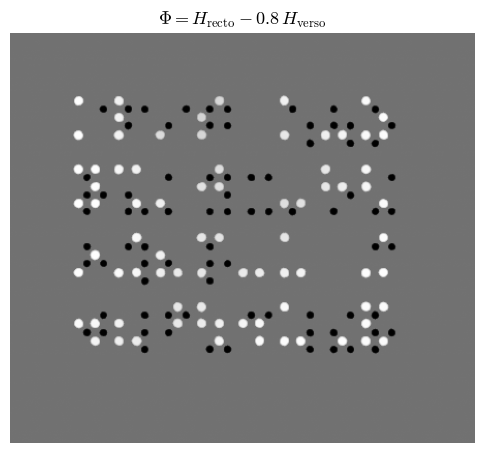

In [10]:
H_verso = np.zeros((H, W), dtype=np.float32)
gamma = 0.8
for r in range(n_rows):
    for c in range(n_cols):
        if random.random() > 0.2:
            char_id = random.randint(0, 62)
            bits = id_to_bits(char_id)
            vx = margin + c*c_w + delta/2
            vy = margin + r*c_h + delta/2
            stamp_cell(H_verso, vx, vy, bits, r_d*gamma, delta, delta)

Phi = H_recto_worn - 0.8*H_verso
show(Phi[:int(4*c_h+2*margin), :int(8*c_w+2*margin)], r"$\Phi = H_{\mathrm{recto}} - 0.8\,H_{\mathrm{verso}}$")

## Step 10 — Diffuse Shading
$$S[i,j] \propto \mathbf{n}_{ij}\cdot\mathbf{L} - 1$$

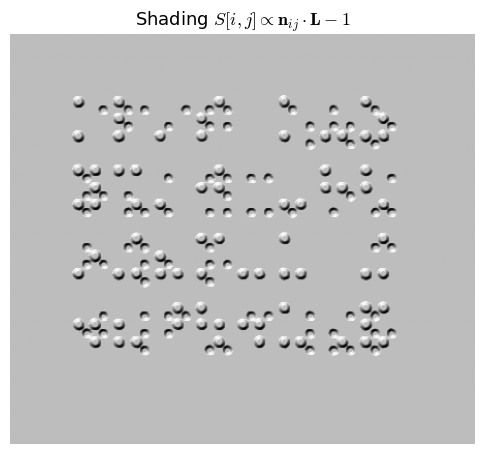

In [11]:
def diffuse_shade(total_h, azimuth_deg=250, elevation_deg=35, intensity=0.35):
    dzdx = cv2.Sobel(total_h, cv2.CV_32F, 1, 0, ksize=3)
    dzdy = cv2.Sobel(total_h, cv2.CV_32F, 0, 1, ksize=3)
    az, el = np.radians(azimuth_deg), np.radians(elevation_deg)
    L = np.array([np.cos(el)*np.cos(az), np.cos(el)*np.sin(az), np.sin(el)], dtype=np.float32)
    mag = np.sqrt(dzdx**2 + dzdy**2 + 1)
    nx, ny, nz = -dzdx/mag, -dzdy/mag, 1.0/mag
    diffuse = nx*L[0] + ny*L[1] + nz*L[2]
    return (diffuse - 1.0) * intensity

S = diffuse_shade(Phi)
show(S[:int(4*c_h+2*margin), :int(8*c_w+2*margin)], r"Shading $S[i,j] \propto \mathbf{n}_{ij}\cdot\mathbf{L} - 1$")

## Step 11 — Paper Texture, Light Gradient, Vignette, Color Tint
$$I = P + S + L_g - \beta_v H_{\text{verso}}$$

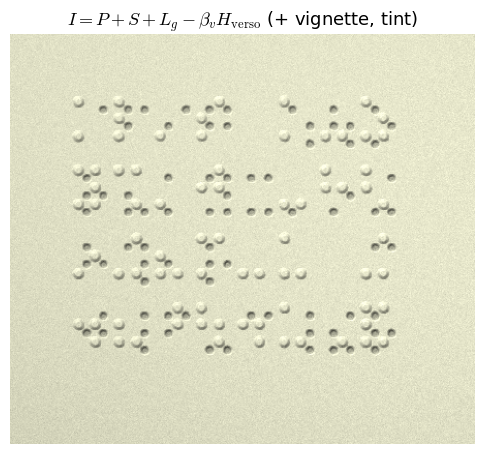

In [12]:
def paper_texture(H, W):
    texture = np.full((H,W), 1.01, dtype=np.float32)
    grain = np.random.normal(0.0025, 0.0275, (H,W))
    small = np.random.normal(0, 0.08, (H//20, W//20))
    clouds = cv2.resize(small, (W,H), interpolation=cv2.INTER_CUBIC)
    clouds = cv2.GaussianBlur(clouds, (15,15), 0)
    return texture + grain + clouds*0.005

def light_gradient(H, W, azimuth_deg, strength=0.18):
    y = np.linspace(-1,1,H, dtype=np.float32)
    x = np.linspace(-1,1,W, dtype=np.float32)
    xv, yv = np.meshgrid(x,y)
    az = np.radians(azimuth_deg)
    ux, uy = np.cos(az), np.sin(az)
    grad = (xv*ux + yv*uy) / max(abs(ux)+abs(uy), 1e-6)
    return grad * strength

def vignette(img, strength=0.25):
    rows, cols = img.shape[:2]
    kx = cv2.getGaussianKernel(cols, cols/2)
    ky = cv2.getGaussianKernel(rows, rows/2)
    v = (ky*kx.T); v /= v.max()
    return img * ((1-strength) + strength*v)

P = paper_texture(H, W)
Lg = light_gradient(H, W, azimuth_deg=250)
beta_v = 0.25
final = P + S + Lg - beta_v*H_verso
final = vignette(final)

final_bgr = np.stack([final]*3, axis=-1)
temp = 0.6
final_bgr[:,:,2] *= (1 - abs(temp)*0.2)   # simple warm tint

final_disp = np.clip(final_bgr, 0, 1)
show(final_disp[:int(4*c_h+2*margin), :int(8*c_w+2*margin)], r"$I = P + S + L_g - \beta_v H_{\mathrm{verso}}$ (+ vignette, tint)", cmap=None)

## Step 12 — Perspective Warp
$$I' = \mathcal{W}_M(I), \qquad M \in \mathbb{R}^{3\times 3}$$

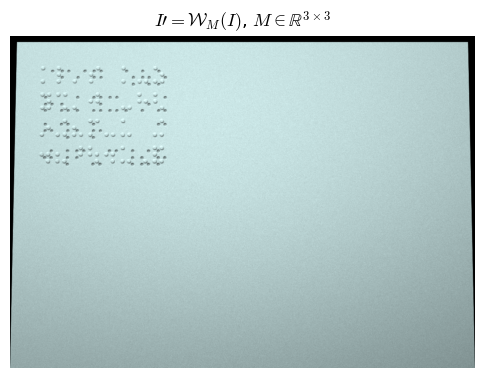

In [13]:
h_img, w_img = final_disp.shape[:2]
src = np.float32([[0,0],[w_img-1,0],[0,h_img-1],[w_img-1,h_img-1]])
tilt = 25 * (s/10)
dst = src.copy()
dst[0][0] += tilt; dst[1][0] -= tilt
dst[0][1] += tilt; dst[1][1] += tilt

Mh = cv2.getPerspectiveTransform(src, dst)
warped = cv2.warpPerspective((final_disp*255).astype(np.uint8), Mh, (w_img, h_img),
                              flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=(0,0,0))

mask = cv2.warpPerspective(np.ones((h_img,w_img), dtype=np.float32), Mh, (w_img,h_img),
                            flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=0)
mask = np.clip(mask, 0, 1)[..., None]
background = np.zeros((h_img, w_img, 3), dtype=np.float32)
warped_final = warped * mask + background*255*(1-mask)
warped_final = warped_final.astype(np.uint8)

show(cv2.cvtColor(warped_final, cv2.COLOR_BGR2RGB), r"$I\prime = \mathcal{W}_M(I)$, $M \in \mathbb{R}^{3\times 3}$", cmap=None)

## Step 13 — Box Transform, Normalization, and Downsampling
$$\hat x_c=\frac{x_1+x_2}{2W},\ \hat y_c=\frac{y_1+y_2}{2H},\ \hat w=\frac{x_2-x_1}{W},\ \hat h=\frac{y_2-y_1}{H}$$

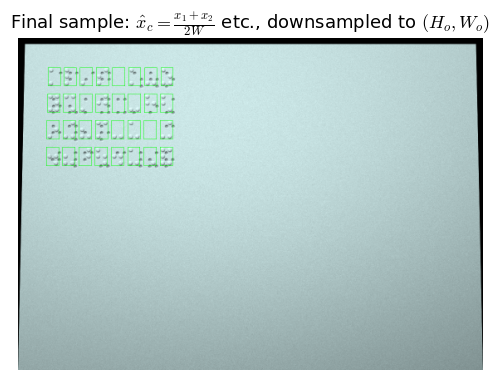

Generated 32 boxes. Example:
0.0779 0.1192 0.0267 0.0556


In [14]:
warped_boxes = []
for (x1,y1,x2,y2) in boxes:
    pts = np.float32([[x1,y1],[x2,y1],[x2,y2],[x1,y2]]).reshape(-1,1,2)
    wp = cv2.perspectiveTransform(pts, Mh)
    nx1, ny1 = wp[:,0,0].min(), wp[:,0,1].min()
    nx2, ny2 = wp[:,0,0].max(), wp[:,0,1].max()
    nx1, nx2 = max(0,nx1), min(w_img,nx2)
    ny1, ny2 = max(0,ny1), min(h_img,ny2)
    if nx2>nx1 and ny2>ny1:
        warped_boxes.append((nx1,ny1,nx2,ny2))

vis2 = warped_final.copy()
for (x1,y1,x2,y2) in warped_boxes:
    cv2.rectangle(vis2, (int(x1),int(y1)), (int(x2),int(y2)), (0,255,0), 1)

output_final = cv2.resize(vis2, (W_o, H_o), interpolation=cv2.INTER_AREA)
show(cv2.cvtColor(output_final, cv2.COLOR_BGR2RGB), r"Final sample: $\hat{x}_c=\frac{x_1+x_2}{2W}$ etc., downsampled to $(H_o,W_o)$", cmap=None)

yolo_annotations = []
for (x1,y1,x2,y2) in warped_boxes:
    xc = (x1+x2)/(2*w_img); yc = (y1+y2)/(2*h_img)
    ww = (x2-x1)/w_img; hh = (y2-y1)/h_img
    yolo_annotations.append(f"{xc:.4f} {yc:.4f} {ww:.4f} {hh:.4f}")

print(f"Generated {len(yolo_annotations)} boxes. Example:")
print(yolo_annotations[0] if yolo_annotations else "none")